# BLAKE3PLUS Benchmark Visualizations

This notebook generates high-resolution dark-themed benchmark figures comparing **BLAKE3PLUS** with upstream **BLAKE3**, **BLAKE2b**, and **SHA-256**.

### Test Environment:
- **CPU**: Intel Core i5-12400F (6 Cores / 12 Threads, AVX2)
- **OS**: Linux 7.1.5 (x86_64)
- **Compiler**: GCC 13.3.0 (`-O3 -march=native`), Rust 1.87-nightly / stable

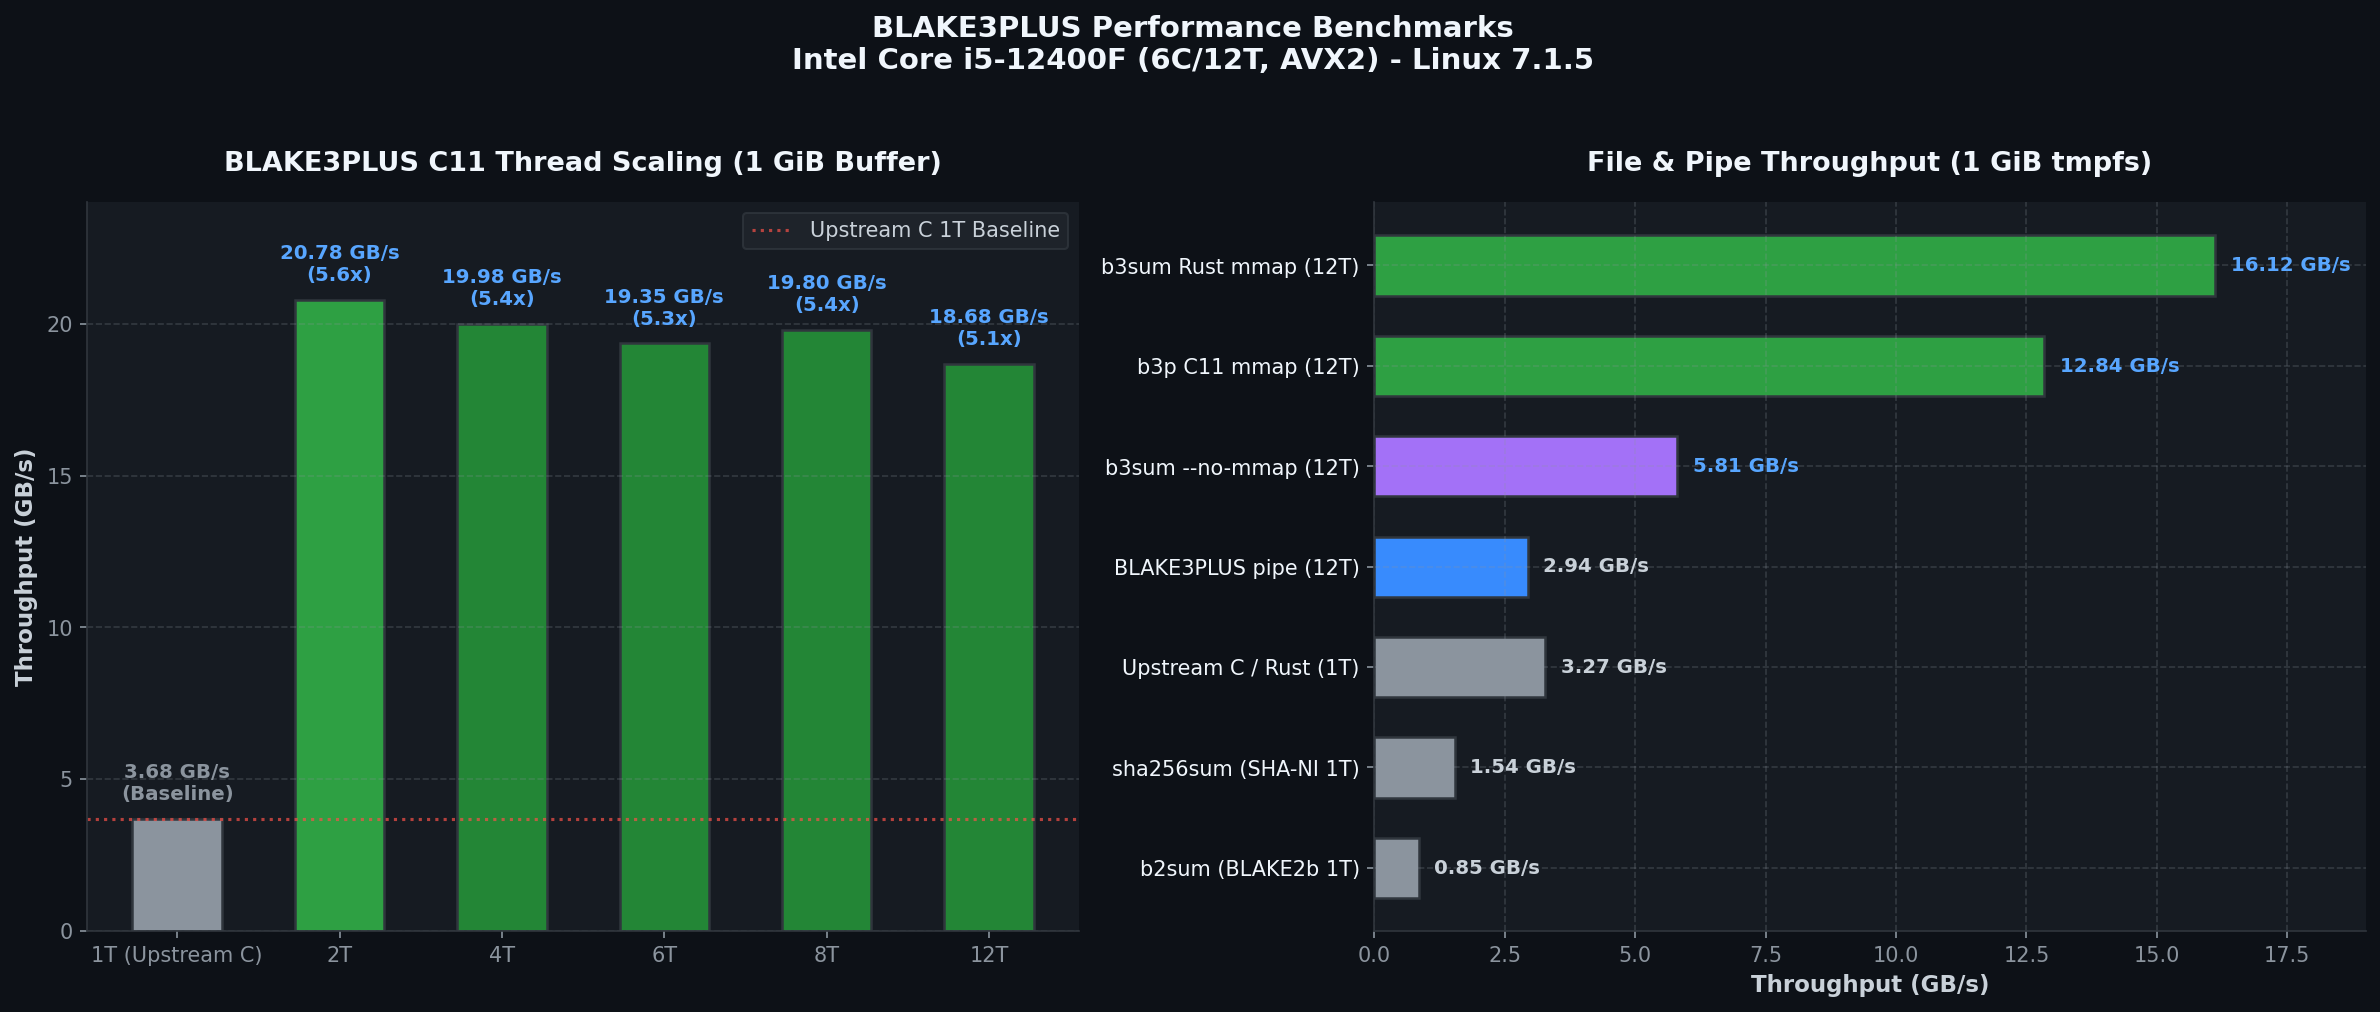

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Set modern dark developer palette
plt.style.use('dark_background')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), dpi=300)
fig.patch.set_facecolor('#0d1117')

for ax in (ax1, ax2):
    ax.set_facecolor('#161b22')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#30363d')
    ax.spines['bottom'].set_color('#30363d')
    ax.tick_params(colors='#8b949e', labelsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.25, color='#8b949e')

# In-memory scaling (1 GiB buffer)
threads = ['1T (Upstream C)', '2T', '4T', '6T', '8T', '12T']
throughput_scaling = [3.68, 20.78, 19.98, 19.35, 19.80, 18.68]
colors1 = ['#8b949e', '#2ea043', '#238636', '#238636', '#238636', '#238636']

bars1 = ax1.bar(threads, throughput_scaling, color=colors1, width=0.55, edgecolor='#30363d', linewidth=1.2)
ax1.set_title('BLAKE3PLUS C11 Thread Scaling (1 GiB Buffer)', fontsize=13, fontweight='bold', color='#f0f6fc', pad=15)
ax1.set_ylabel('Throughput (GB/s)', fontsize=11, color='#c9d1d9', fontweight='600')
ax1.set_ylim(0, 24)

for bar in bars1:
    yval = bar.get_height()
    speedup = f"{yval / 3.68:.1f}x" if yval > 4.0 else "Baseline"
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{yval:.2f} GB/s\n({speedup})", 
             ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#58a6ff' if yval > 4 else '#8b949e')

ax1.axhline(3.68, color='#f85149', linestyle=':', alpha=0.7, label='Upstream C 1T Baseline')
ax1.legend(loc='upper right', frameon=True, facecolor='#21262d', edgecolor='#30363d', labelcolor='#c9d1d9')

# File & pipe throughput comparison (1 GiB tmpfs)
tools = [
    'b2sum (BLAKE2b 1T)',
    'sha256sum (SHA-NI 1T)',
    'Upstream C / Rust (1T)',
    'BLAKE3PLUS pipe (12T)',
    'b3sum --no-mmap (12T)',
    'b3p C11 mmap (12T)',
    'b3sum Rust mmap (12T)'
]
cli_throughput = [0.85, 1.54, 3.27, 2.94, 5.81, 12.84, 16.12]
colors2 = ['#8b949e', '#8b949e', '#8b949e', '#388bfd', '#a371f7', '#2ea043', '#2ea043']

y_pos = np.arange(len(tools))
bars2 = ax2.barh(y_pos, cli_throughput, color=colors2, height=0.6, edgecolor='#30363d', linewidth=1.2)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(tools, fontsize=10, color='#f0f6fc')
ax2.set_title('File & Pipe Throughput (1 GiB tmpfs)', fontsize=13, fontweight='bold', color='#f0f6fc', pad=15)
ax2.set_xlabel('Throughput (GB/s)', fontsize=11, color='#c9d1d9', fontweight='600')
ax2.set_xlim(0, 19)
ax2.grid(axis='x', linestyle='--', alpha=0.25, color='#8b949e')

for bar in bars2:
    xval = bar.get_width()
    ax2.text(xval + 0.3, bar.get_y() + bar.get_height()/2.0, f"{xval:.2f} GB/s", 
             ha='left', va='center', fontsize=9.5, fontweight='bold', color='#58a6ff' if xval >= 5 else '#c9d1d9')

fig.suptitle('BLAKE3PLUS Performance Benchmarks\nIntel Core i5-12400F (6C/12T, AVX2) - Linux 7.1.5', 
             fontsize=14, fontweight='bold', color='#f0f6fc', y=1.03)

plt.tight_layout()
plt.show()
